# Tarefa 2 — Modelos de Classificação e Regressão com Redes Neuronais

**Curso de Especialização em Deep Learning** · Pedro Serrano · setembro de 2026

Neste notebook desenvolvo, treino e avalio duas redes neuronais densas (MLP, *multilayer perceptron*) com TensorFlow/Keras, uma para cada tipo de problema de aprendizagem supervisionada:

| Parte | Problema | Dataset | Camada de saída | Função de perda |
|:--|:--|:--|:--|:--|
| 1 | Classificação multiclasse | Fashion-MNIST (70 000 imagens, 10 classes) | 10 neurónios, Softmax | `sparse_categorical_crossentropy` |
| 2 | Regressão | California Housing (20 640 zonas, 8 atributos) | 1 neurónio, linear | `mse` |
| 3 | Comparação e análise dos dois modelos | — | — | — |

**Estrutura:** 0. Configuração · 1. Classificação · 2. Regressão · 3. Comparação e análise · 4. Conclusões

> As figuras ficam guardadas na pasta `figuras/` e as métricas finais em `resultados/metricas.json`; são a base do relatório em PDF.

## 0. Configuração do ambiente

Importação das bibliotecas, fixação da semente aleatória (para os resultados serem reprodutíveis) e duas funções auxiliares usadas nas duas partes: um *callback* que resume o treino e uma função que desenha as curvas de aprendizagem.

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # esconde as mensagens informativas do TensorFlow

import json
import platform
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import tensorflow as tf
import keras
from keras import layers

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             mean_absolute_error, mean_squared_error, r2_score)

# Semente fixa: a divisão dos dados e a inicialização dos pesos repetem-se em cada execução
SEMENTE = 42
keras.utils.set_random_seed(SEMENTE)   # fixa as sementes do Python, do NumPy e do TensorFlow

# Pastas para as figuras e as métricas usadas no relatório
os.makedirs("figuras", exist_ok=True)
os.makedirs("resultados", exist_ok=True)

# Estilo comum dos gráficos
plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 12,
                     "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

print("Python:", platform.python_version(), "| TensorFlow:", tf.__version__,
      "| Keras:", keras.__version__, "| scikit-learn:", sklearn.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU") or "não (treino em CPU)")

Python: 3.12.6 | TensorFlow: 2.21.0 | Keras: 3.15.1 | scikit-learn: 1.8.0
GPU disponível: não (treino em CPU)


In [2]:
class ResumoEpocas(keras.callbacks.Callback):
    """Imprime uma linha de resumo a cada `cada` épocas, em vez de uma barra de
    progresso por época, para o registo do treino ficar curto e legível."""

    def __init__(self, cada=5):
        super().__init__()
        self.cada = cada

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if epoch == 0 or (epoch + 1) % self.cada == 0:
            valores = "  ".join(f"{nome}={valor:.4f}" for nome, valor in logs.items()
                                if nome != "learning_rate")
            print(f"Época {epoch + 1:3d} | {valores}")


def grafico_curvas(historico, metricas, titulos, ficheiro, melhor_epoca=None, escala_log=()):
    """Desenha, lado a lado, a evolução de cada métrica no treino e na validação.

    historico    : dicionário History.history devolvido por model.fit()
    metricas     : métricas a desenhar (ex.: ["loss", "accuracy"])
    titulos      : título de cada gráfico
    ficheiro     : nome do PNG guardado em figuras/
    melhor_epoca : época escolhida pela paragem antecipada (linha vertical tracejada)
    escala_log   : métricas a desenhar em escala logarítmica
    """
    fig, eixos = plt.subplots(1, len(metricas), figsize=(5.0 * len(metricas), 3.8))
    epocas = np.arange(1, len(historico["loss"]) + 1)
    for eixo, metrica, titulo in zip(np.atleast_1d(eixos), metricas, titulos):
        eixo.plot(epocas, historico[metrica], lw=2, label="Treino")
        eixo.plot(epocas, historico["val_" + metrica], lw=2, label="Validação")
        if melhor_epoca is not None:
            eixo.axvline(melhor_epoca, color="gray", ls="--", lw=1.2,
                         label=f"Melhor época ({melhor_epoca})")
        if metrica in escala_log:
            eixo.set_yscale("log")
        eixo.set_title(titulo)
        eixo.set_xlabel("Época")
        eixo.legend()
    fig.tight_layout()
    fig.savefig(f"figuras/{ficheiro}", dpi=200, bbox_inches="tight")
    plt.show()


def fmt(n):
    """Formata um inteiro com espaço como separador de milhares (ex.: 235 146)."""
    return f"{n:,}".replace(",", " ")

---
## Parte 1 — Modelo de Classificação (Fashion-MNIST)

### 1.1 Dataset

Escolhi o **Fashion-MNIST** (Zalando, 2017): 70 000 imagens de artigos de vestuário em tons de cinzento, com 28 × 28 píxeis, divididas em **10 classes equilibradas** (60 000 imagens de treino e 10 000 de teste). Tem o mesmo formato do MNIST, mas é bastante mais difícil: um MLP simples ultrapassa os 97 % no MNIST e fica perto dos 88–90 % no Fashion-MNIST. Isso torna mais visíveis as diferenças entre modelos e deixa erros interessantes para analisar.

In [3]:
# O Keras descarrega o dataset na primeira execução (≈ 30 MB) e guarda-o em cache (~/.keras/datasets)
(X_treino_full, y_treino_full), (X_teste_clf, y_teste_clf) = keras.datasets.fashion_mnist.load_data()

# Nomes das 10 classes, pela ordem das etiquetas 0-9
NOMES_CLASSES = ["T-shirt/top", "Calças", "Camisola", "Vestido", "Casaco",
                 "Sandália", "Camisa", "Sapatilha", "Mala", "Botim"]

print("Treino:", X_treino_full.shape, X_treino_full.dtype, "| etiquetas:", y_treino_full.shape)
print("Teste :", X_teste_clf.shape, X_teste_clf.dtype, "| etiquetas:", y_teste_clf.shape)
print("Valores dos píxeis: mínimo =", X_treino_full.min(), "| máximo =", X_treino_full.max())
print("Imagens de treino por classe:", np.bincount(y_treino_full))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Treino: (60000, 28, 28) uint8 | etiquetas: (60000,)
Teste : (10000, 28, 28) uint8 | etiquetas: (10000,)
Valores dos píxeis: mínimo = 0 | máximo = 255
Imagens de treino por classe: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


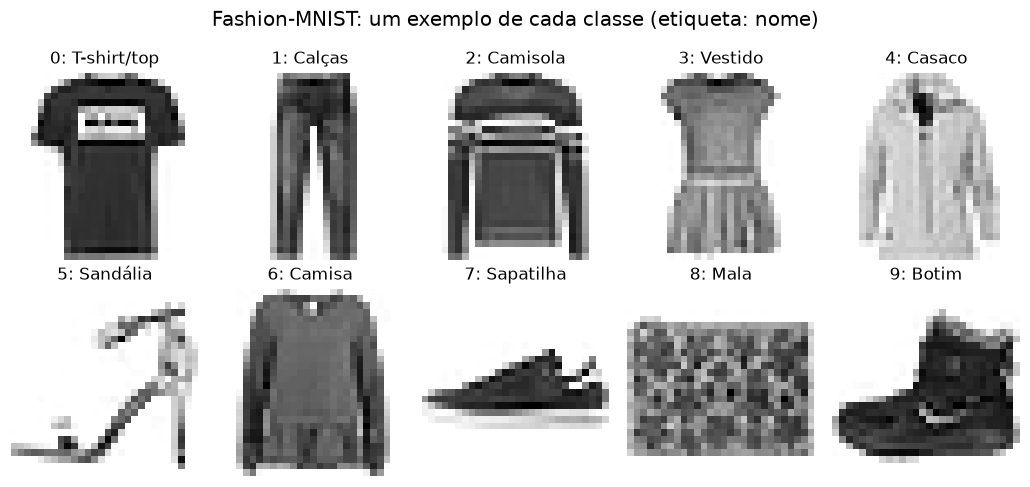

In [4]:
# Uma imagem de cada classe (a primeira que aparece no conjunto de treino)
fig, eixos = plt.subplots(2, 5, figsize=(9.5, 4.6))
for classe, eixo in enumerate(eixos.ravel()):
    indice = np.where(y_treino_full == classe)[0][0]
    eixo.imshow(X_treino_full[indice], cmap="gray_r")
    eixo.set_title(f"{classe}: {NOMES_CLASSES[classe]}", fontsize=11)
    eixo.axis("off")
fig.suptitle("Fashion-MNIST: um exemplo de cada classe (etiqueta: nome)", fontsize=13)
fig.tight_layout()
fig.savefig("figuras/clf_01_exemplos.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.2 Pré-processamento

- **Normalização:** os píxeis passam de inteiros em [0, 255] para reais em [0, 1]. Com entradas pequenas, as somas ponderadas das primeiras camadas também ficam pequenas e os gradientes ficam numa escala adequada para o otimizador (a Parte 3 mostra o que acontece sem este passo).
- **Conjunto de validação:** separo 10 % das imagens de treino (6 000), de forma estratificada, para acompanhar o treino e decidir quando parar. O conjunto de teste só é usado no fim, uma única vez.
- **Etiquetas:** ficam como inteiros de 0 a 9, por isso a perda adequada é a `sparse_categorical_crossentropy`. Com etiquetas em *one-hot*, usar-se-ia a `categorical_crossentropy`; as duas calculam exatamente o mesmo valor (verificado na secção 1.4).

In [5]:
# 1) Normalização: píxeis de [0, 255] (uint8) para [0, 1] (float32)
X_treino_full = X_treino_full.astype("float32") / 255.0
X_teste_clf = X_teste_clf.astype("float32") / 255.0

# 2) Validação: 10 % do treino, estratificado (mantém a proporção de cada classe)
X_treino_clf, X_val_clf, y_treino_clf, y_val_clf = train_test_split(
    X_treino_full, y_treino_full, test_size=0.10, stratify=y_treino_full, random_state=SEMENTE)
del X_treino_full   # já não é necessário; liberta memória

print(f"Treino: {len(X_treino_clf)} | Validação: {len(X_val_clf)} | Teste: {len(X_teste_clf)}")
print(f"Píxeis depois da normalização: [{X_treino_clf.min():.1f}, {X_treino_clf.max():.1f}]")
print("Primeiras 10 etiquetas de treino:", y_treino_clf[:10], "-> inteiros de 0 a 9")

Treino: 54000 | Validação: 6000 | Teste: 10000
Píxeis depois da normalização: [0.0, 1.0]
Primeiras 10 etiquetas de treino: [8 9 8 0 1 9 4 6 6 8] -> inteiros de 0 a 9


### 1.3 Arquitetura da rede

| Camada | Configuração | Função |
|:--|:--|:--|
| Entrada | `Input(shape=(28, 28))` | Recebe uma imagem 28 × 28 |
| Achatamento | `Flatten()` | Converte a imagem num vetor de 784 valores (as camadas densas só aceitam vetores) |
| Oculta 1 | `Dense(256, activation="relu")` | Primeira camada oculta densa |
| Dropout | `Dropout(0.2)` | Desliga ao acaso 20 % dos neurónios em cada passo de treino (regularização) |
| Oculta 2 | `Dense(128, activation="relu")` | Segunda camada oculta densa |
| Dropout | `Dropout(0.2)` | Regularização |
| Saída | `Dense(10, activation="softmax")` | Uma probabilidade por classe; as 10 somam 1 |

A **ReLU**, $f(x)=\max(0, x)$, é barata de calcular e não satura para valores positivos, o que atenua o desvanecimento do gradiente. A **Softmax** transforma os 10 valores da última camada numa distribuição de probabilidades, e a classe prevista é a de maior probabilidade. O **dropout** combate o sobreajuste: sem ele, uma rede com mais de 200 mil parâmetros começa rapidamente a decorar as imagens de treino.

In [6]:
def criar_classificador(taxa_dropout=0.2):
    """Cria o MLP de classificação: 784 entradas -> 256 -> 128 -> 10 classes."""
    return keras.Sequential([
        layers.Input(shape=(28, 28), name="entrada"),          # camada de entrada (imagem 28x28)
        layers.Flatten(name="achatamento"),                      # 28x28 -> vetor de 784 valores
        layers.Dense(256, activation="relu", name="oculta_1"),   # 1.ª camada oculta densa (ReLU)
        layers.Dropout(taxa_dropout, name="dropout_1"),          # regularização
        layers.Dense(128, activation="relu", name="oculta_2"),   # 2.ª camada oculta densa (ReLU)
        layers.Dropout(taxa_dropout, name="dropout_2"),          # regularização
        layers.Dense(10, activation="softmax", name="saida"),    # 10 probabilidades (Softmax)
    ], name="classificador_fashion_mnist")


keras.utils.set_random_seed(SEMENTE)   # mesma inicialização dos pesos em cada execução
modelo_clf = criar_classificador()
modelo_clf.summary()

Model: "classificador_fashion_mnist"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ achatamento (Flatten)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

A rede tem **235 146 parâmetros treináveis**, 85 % dos quais na primeira camada oculta, que liga cada um dos 784 píxeis a cada um dos 256 neurónios (784 × 256 pesos + 256 vieses = 200 960).

### 1.4 Compilação

- **Otimizador:** Adam, com taxa de aprendizagem de 0,001 (o valor de referência deste otimizador).
- **Perda:** `sparse_categorical_crossentropy`, a entropia cruzada categórica para etiquetas inteiras, $\mathcal{L} = -\log \hat{p}_{y}$: penaliza o modelo quando atribui pouca probabilidade à classe correta.
- **Métrica:** `accuracy` (acurácia), a fração de imagens bem classificadas.

In [7]:
modelo_clf.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",   # etiquetas inteiras 0-9
    metrics=["accuracy"],
)

# Verificação: com as etiquetas em one-hot, a categorical_crossentropy dá o mesmo valor.
# Com o modelo ainda por treinar, a perda deve andar perto de ln(10) ≈ 2.30, o valor de quem
# atribui a mesma probabilidade às 10 classes (um palpite ao acaso).
amostra_x, amostra_y = X_val_clf[:1000], y_val_clf[:1000]
prob_iniciais = modelo_clf.predict(amostra_x, verbose=0)
perda_sparse = float(keras.losses.SparseCategoricalCrossentropy()(amostra_y, prob_iniciais))
perda_onehot = float(keras.losses.CategoricalCrossentropy()(
    keras.utils.to_categorical(amostra_y, 10), prob_iniciais))
print(f"sparse_categorical_crossentropy (etiquetas inteiras): {perda_sparse:.4f}")
print(f"categorical_crossentropy (etiquetas one-hot)        : {perda_onehot:.4f}")
print(f"ln(10)                                              : {np.log(10):.4f}")

sparse_categorical_crossentropy (etiquetas inteiras): 2.3722
categorical_crossentropy (etiquetas one-hot)        : 2.3722
ln(10)                                              : 2.3026


### 1.5 Treino

Treino com mini-lotes de 128 imagens, até um máximo de 50 épocas, com dois *callbacks*:

- **`EarlyStopping`** — pára o treino quando a perda de validação não melhora durante 6 épocas seguidas e repõe os pesos da melhor época, para não ficar com um modelo sobreajustado;
- **`ReduceLROnPlateau`** — divide a taxa de aprendizagem por 2 quando a perda de validação estagna 3 épocas, o que permite ajustes mais finos na fase final.

In [8]:
callbacks_clf = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
    ResumoEpocas(cada=5),
]

inicio = time.perf_counter()
historico_clf = modelo_clf.fit(
    X_treino_clf, y_treino_clf,
    validation_data=(X_val_clf, y_val_clf),   # avaliado no fim de cada época
    epochs=50, batch_size=128,
    callbacks=callbacks_clf, verbose=0)
tempo_clf = time.perf_counter() - inicio

hist_clf = historico_clf.history
melhor_epoca_clf = int(np.argmin(hist_clf["val_loss"])) + 1
print(f"\nTreino concluído em {tempo_clf:.0f} s | épocas executadas: {len(hist_clf['loss'])}"
      f" | melhor época: {melhor_epoca_clf}")

Época   1 | accuracy=0.7906  loss=0.5923  val_accuracy=0.8538  val_loss=0.4013
Época   5 | accuracy=0.8782  loss=0.3310  val_accuracy=0.8895  val_loss=0.3063
Época  10 | accuracy=0.8945  loss=0.2801  val_accuracy=0.8977  val_loss=0.2816

Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Época  15 | accuracy=0.9142  loss=0.2270  val_accuracy=0.9012  val_loss=0.2723

Epoch 19: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
Época  20 | accuracy=0.9263  loss=0.1951  val_accuracy=0.9065  val_loss=0.2647

Epoch 22: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Epoch 22: early stopping
Restoring model weights from the end of the best epoch: 16.

Treino concluído em 63 s | épocas executadas: 22 | melhor época: 16


### 1.6 Evolução da perda e da acurácia

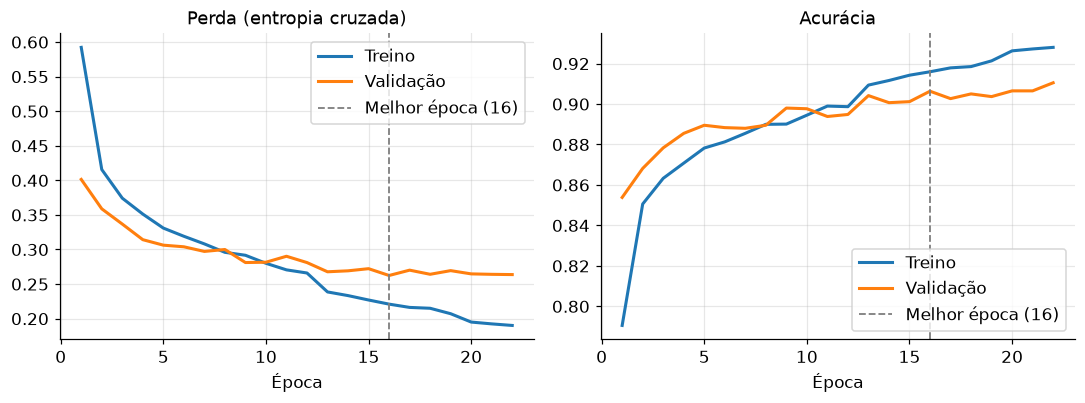

Melhor época (16): perda treino = 0.2210 | perda validação = 0.2624
                  acurácia treino = 0.9159 | acurácia validação = 0.9063


In [9]:
grafico_curvas(hist_clf, metricas=["loss", "accuracy"],
               titulos=["Perda (entropia cruzada)", "Acurácia"],
               ficheiro="clf_02_curvas_treino.png", melhor_epoca=melhor_epoca_clf)

i = melhor_epoca_clf - 1
print(f"Melhor época ({melhor_epoca_clf}): perda treino = {hist_clf['loss'][i]:.4f} | "
      f"perda validação = {hist_clf['val_loss'][i]:.4f}")
print(f"{'':>17} acurácia treino = {hist_clf['accuracy'][i]:.4f} | "
      f"acurácia validação = {hist_clf['val_accuracy'][i]:.4f}")

**Leitura das curvas.** Nas primeiras épocas, a perda desce depressa nos dois conjuntos, e a acurácia de validação chega aos 89 % logo na 5.ª época. A partir daí, a perda de treino continua a descer a bom ritmo, mas a de validação desce muito mais devagar e com oscilações. Por volta da 10.ª época, a perda de treino passa para baixo da de validação e a diferença entre as duas vai aumentando: é o início do sobreajuste (*overfitting*), em que a rede se ajusta a pormenores das imagens de treino que não se repetem noutras imagens. A taxa de aprendizagem foi reduzida para metade nas épocas 12 e 19, o que ajuda a afinar os pesos na fase final (a terceira redução, na época 22, coincidiu com a paragem). O mínimo da perda de validação (0,2624) foi atingido na época 16. Como não houve melhorias nas 6 épocas seguintes, o treino parou na época 22 e os pesos da época 16 foram repostos. Nessa época, a acurácia era de 91,6 % no treino e de 90,6 % na validação.

*Nota:* as métricas de treino são medidas com o dropout ativo e em média ao longo de cada época, enquanto a rede ainda está a aprender, por isso ficam um pouco pessimistas. Por isso, nas primeiras épocas (até à 9.ª), a perda de treino fica quase sempre acima da de validação.

### 1.7 Avaliação no conjunto de teste

In [10]:
res_clf = modelo_clf.evaluate(X_teste_clf, y_teste_clf, verbose=0, return_dict=True)
print(f"Perda no teste   : {res_clf['loss']:.4f}")
print(f"Acurácia no teste: {res_clf['accuracy']:.4f}  ({res_clf['accuracy'] * 100:.2f} %)\n")

# A rede devolve 10 probabilidades por imagem; a classe prevista é a de maior probabilidade
prob_teste = modelo_clf.predict(X_teste_clf, verbose=0)
y_prev_clf = prob_teste.argmax(axis=1)

# Precisão, recall (sensibilidade) e F1 de cada classe
relatorio_clf = classification_report(y_teste_clf, y_prev_clf, target_names=NOMES_CLASSES,
                                      digits=3, output_dict=True)
print(classification_report(y_teste_clf, y_prev_clf, target_names=NOMES_CLASSES, digits=3))

Perda no teste   : 0.3134
Acurácia no teste: 0.8916  (89.16 %)

              precision    recall  f1-score   support

 T-shirt/top      0.837     0.858     0.847      1000
      Calças      0.993     0.976     0.984      1000
    Camisola      0.815     0.792     0.803      1000
     Vestido      0.884     0.914     0.899      1000
      Casaco      0.803     0.833     0.817      1000
    Sandália      0.982     0.964     0.973      1000
      Camisa      0.729     0.682     0.705      1000
   Sapatilha      0.924     0.976     0.949      1000
        Mala      0.972     0.980     0.976      1000
       Botim      0.974     0.941     0.957      1000

    accuracy                          0.892     10000
   macro avg      0.891     0.892     0.891     10000
weighted avg      0.891     0.892     0.891     10000



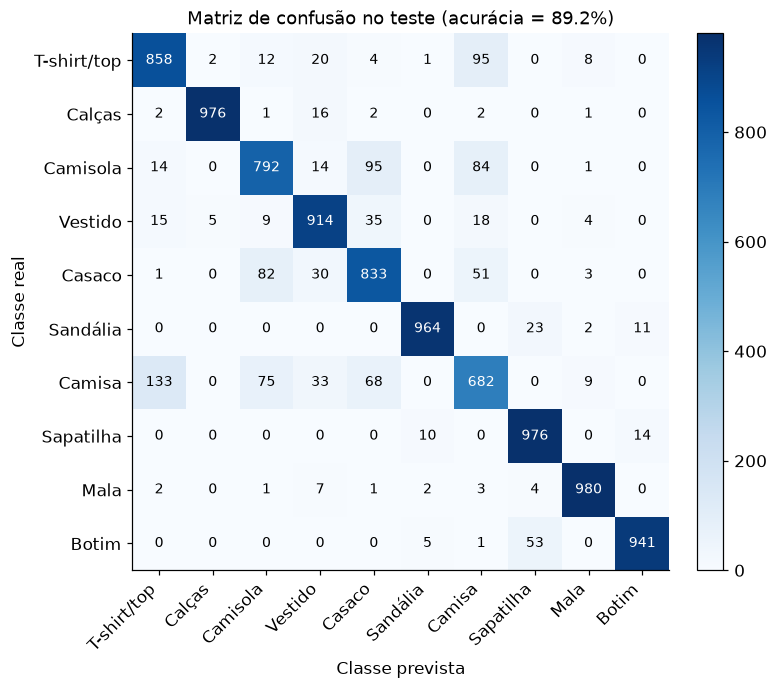

Confusões mais frequentes (real -> prevista):
       Camisa -> T-shirt/top  133 imagens
     Camisola -> Casaco        95 imagens
  T-shirt/top -> Camisa        95 imagens
     Camisola -> Camisa        84 imagens
       Casaco -> Camisola      82 imagens


In [11]:
matriz = confusion_matrix(y_teste_clf, y_prev_clf)

fig, eixo = plt.subplots(figsize=(7.6, 6.4))
imagem = eixo.imshow(matriz, cmap="Blues")
eixo.set_xticks(range(10), NOMES_CLASSES, rotation=45, ha="right")
eixo.set_yticks(range(10), NOMES_CLASSES)
limiar = matriz.max() / 2
for i in range(10):
    for j in range(10):
        eixo.text(j, i, matriz[i, j], ha="center", va="center", fontsize=9,
                  color="white" if matriz[i, j] > limiar else "black")
eixo.set_xlabel("Classe prevista")
eixo.set_ylabel("Classe real")
eixo.set_title(f"Matriz de confusão no teste (acurácia = {res_clf['accuracy']:.1%})")
eixo.grid(False)
fig.colorbar(imagem, ax=eixo, fraction=0.046, pad=0.04)
fig.tight_layout()
fig.savefig("figuras/clf_03_matriz_confusao.png", dpi=200, bbox_inches="tight")
plt.show()

# As 5 confusões mais frequentes (fora da diagonal)
fora_diagonal = matriz.copy()
np.fill_diagonal(fora_diagonal, 0)
ordem = np.argsort(fora_diagonal, axis=None)[::-1][:5]
confusoes_top = []
print("Confusões mais frequentes (real -> prevista):")
for real, prevista in zip(*np.unravel_index(ordem, matriz.shape)):
    confusoes_top.append((NOMES_CLASSES[real], NOMES_CLASSES[prevista], int(fora_diagonal[real, prevista])))
    print(f"  {NOMES_CLASSES[real]:>11} -> {NOMES_CLASSES[prevista]:<11} {fora_diagonal[real, prevista]:4d} imagens")

Imagens mal classificadas: 1084 de 10000
Confiança média nas previsões certas : 93.6%
Confiança média nas previsões erradas: 68.6%


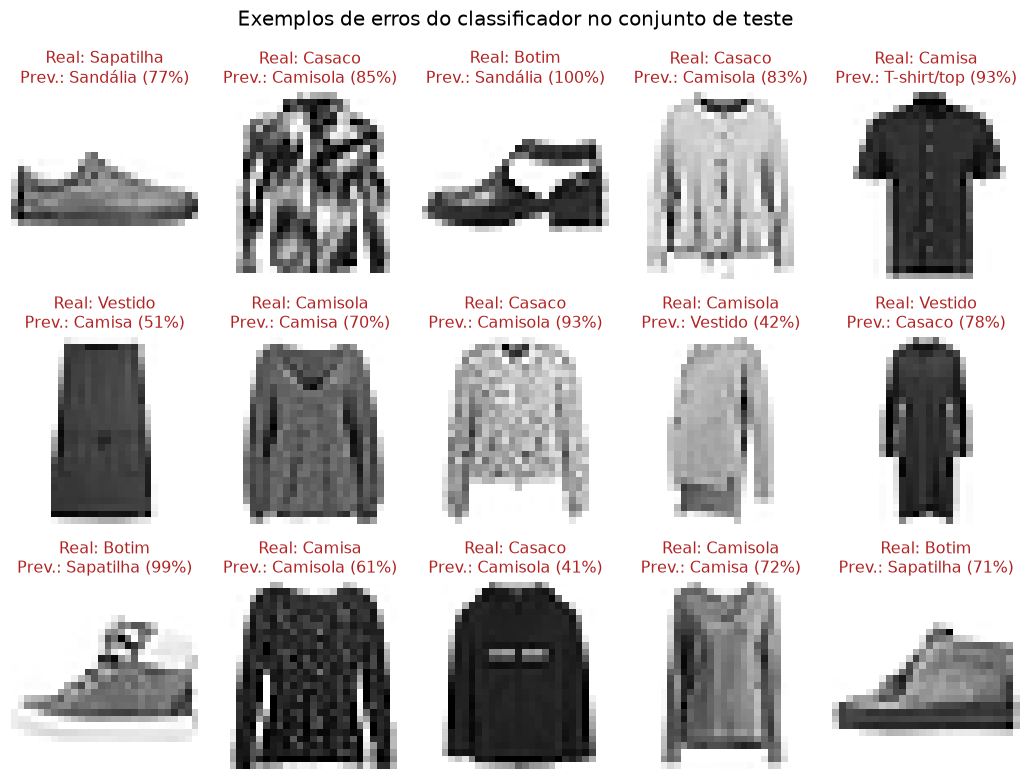

In [12]:
# Exemplos de imagens mal classificadas, com a confiança (probabilidade) da previsão errada
erros = np.where(y_prev_clf != y_teste_clf)[0]
confianca = prob_teste.max(axis=1)
print(f"Imagens mal classificadas: {len(erros)} de {len(y_teste_clf)}")
print(f"Confiança média nas previsões certas : {confianca[y_prev_clf == y_teste_clf].mean():.1%}")
print(f"Confiança média nas previsões erradas: {confianca[erros].mean():.1%}")

fig, eixos = plt.subplots(3, 5, figsize=(9.5, 7.4))
for eixo, indice in zip(eixos.ravel(), erros[:15]):
    eixo.imshow(X_teste_clf[indice], cmap="gray_r")
    eixo.set_title(f"Real: {NOMES_CLASSES[y_teste_clf[indice]]}\n"
                   f"Prev.: {NOMES_CLASSES[y_prev_clf[indice]]} ({confianca[indice]:.0%})",
                   fontsize=10.5, color="firebrick")
    eixo.axis("off")
fig.suptitle("Exemplos de erros do classificador no conjunto de teste", fontsize=13)
fig.tight_layout()
fig.savefig("figuras/clf_04_erros.png", dpi=200, bbox_inches="tight")
plt.show()

### 1.8 Discussão dos resultados da classificação

- A rede acerta em **89,2 %** das 10 000 imagens de teste (1 084 erros), muito acima dos 10 % de um palpite ao acaso e dentro do que se espera de um MLP neste dataset. A acurácia de teste fica perto da de validação (90,6 %), o que mostra que a validação estimou bem o desempenho em imagens novas.
- Os erros não se distribuem ao acaso. As classes com pior F1 são Camisa (0,70), Camisola (0,80), Casaco (0,82) e T-shirt/top (0,85), todas peças de cima do corpo, com silhuetas muito parecidas a 28 × 28 píxeis. A classe mais difícil é **Camisa**: só 68 % das suas imagens são reconhecidas. As confusões mais frequentes são Camisa → T-shirt/top (133), Camisola → Casaco (95) e T-shirt/top → Camisa (95). No extremo oposto, Calças, Mala, Sandália e Botim têm F1 acima de 0,95.
- Parte desta limitação vem da arquitetura: o `Flatten` transforma a imagem numa lista de píxeis, e a rede perde a noção de vizinhança (contornos, texturas, formas). As redes convolucionais (CNN) exploram essa estrutura e costumam ultrapassar os 91–92 % neste dataset.
- Mesmo quando erra, a rede está muitas vezes confiante: a confiança média é de 93,6 % nas previsões certas, mas ainda de 68,6 % nas erradas. As probabilidades da Softmax não são, por isso, uma medida fiável da incerteza do modelo.

---
## Parte 2 — Modelo de Regressão (California Housing)

### 2.1 Dataset

Escolhi o **California Housing** (censo dos EUA de 1990, incluído no scikit-learn): 20 640 zonas censitárias da Califórnia, descritas por 8 atributos numéricos. O objetivo é prever o **valor mediano das casas** de cada zona, em centenas de milhares de dólares.

Preferi-o ao Boston Housing, sugerido no enunciado, por duas razões:

1. **Dimensão:** tem 20 640 exemplos, contra apenas 506 no Boston Housing. Com tão poucos dados, os resultados de uma rede neuronal variam muito com a divisão treino/teste e com a semente aleatória.
2. **Problemas éticos:** o Boston Housing inclui uma variável construída a partir da proporção de população negra de cada zona e foi retirado do scikit-learn (versão 1.2) por esse motivo. O California Housing é o substituto recomendado.

| Atributo | Significado |
|:--|:--|
| `MedInc` | Rendimento mediano da zona (dezenas de milhares de USD) |
| `HouseAge` | Idade mediana das casas (anos) |
| `AveRooms` | Número médio de divisões por habitação |
| `AveBedrms` | Número médio de quartos por habitação |
| `Population` | População da zona |
| `AveOccup` | Número médio de ocupantes por habitação |
| `Latitude`, `Longitude` | Localização geográfica |
| **`MedHouseVal`** (alvo) | Valor mediano das casas (centenas de milhares de USD) |

In [13]:
# O scikit-learn descarrega o dataset na primeira execução e guarda-o em cache (~/scikit_learn_data)
california = fetch_california_housing(as_frame=True)
df_casas = california.frame   # DataFrame com os 8 atributos e o alvo (MedHouseVal)

print("Dimensão:", df_casas.shape, "| valores em falta:", int(df_casas.isna().sum().sum()))
df_casas.describe().T.round(2)

Dimensão: (20640, 9) | valores em falta: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
MedHouseVal,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


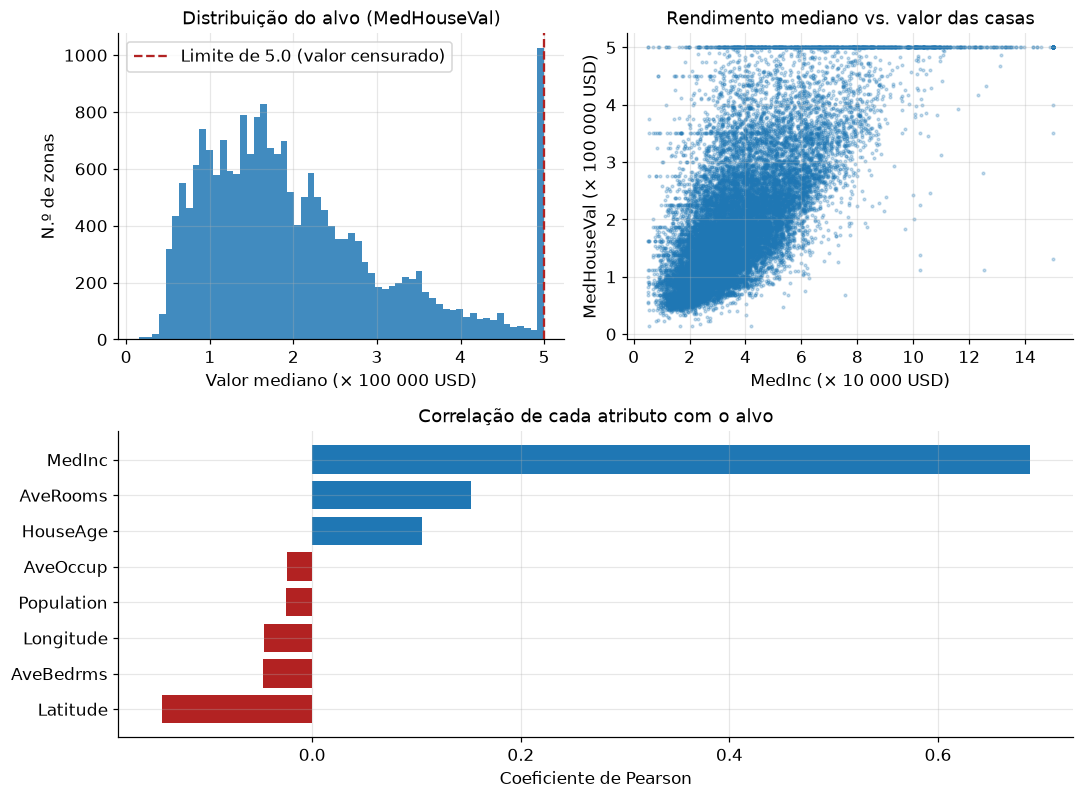

Zonas com o valor no limite (>= 5.0): 992 (4.8%)


In [14]:
fig = plt.figure(figsize=(10, 7.4))
grelha = fig.add_gridspec(2, 2)
eixos = [fig.add_subplot(grelha[0, 0]), fig.add_subplot(grelha[0, 1]), fig.add_subplot(grelha[1, :])]

# (a) Distribuição do alvo: no censo original, os valores estão limitados a 5.0 (500 000 USD)
eixos[0].hist(df_casas["MedHouseVal"], bins=60, color="tab:blue", alpha=0.85)
eixos[0].axvline(5.0, color="firebrick", ls="--", lw=1.5, label="Limite de 5.0 (valor censurado)")
eixos[0].set_title("Distribuição do alvo (MedHouseVal)")
eixos[0].set_xlabel("Valor mediano (× 100 000 USD)")
eixos[0].set_ylabel("N.º de zonas")
eixos[0].legend()

# (b) O rendimento mediano é o atributo mais relacionado com o preço
eixos[1].scatter(df_casas["MedInc"], df_casas["MedHouseVal"], s=3, alpha=0.25)
eixos[1].set_title("Rendimento mediano vs. valor das casas")
eixos[1].set_xlabel("MedInc (× 10 000 USD)")
eixos[1].set_ylabel("MedHouseVal (× 100 000 USD)")

# (c) Correlação linear (Pearson) de cada atributo com o alvo
correlacoes = df_casas.corr()["MedHouseVal"].drop("MedHouseVal").sort_values()
eixos[2].barh(correlacoes.index, correlacoes.values,
              color=["firebrick" if v < 0 else "tab:blue" for v in correlacoes.values])
eixos[2].set_title("Correlação de cada atributo com o alvo")
eixos[2].set_xlabel("Coeficiente de Pearson")

fig.tight_layout()
fig.savefig("figuras/reg_01_exploracao.png", dpi=200, bbox_inches="tight")
plt.show()

n_limite = int((df_casas["MedHouseVal"] >= 5.0).sum())
print(f"Zonas com o valor no limite (>= 5.0): {n_limite} ({n_limite / len(df_casas):.1%})")

### 2.2 Pré-processamento

- **Divisão:** 20 % dos dados para teste e, dos restantes, 20 % para validação: 64 % treino / 16 % validação / 20 % teste.
- **Padronização (*z-score*):** os atributos têm escalas muito diferentes (a `Population` chega às dezenas de milhares, a `AveBedrms` anda perto de 1). O `StandardScaler` põe cada atributo com média 0 e desvio-padrão 1. É **ajustado apenas com o treino** e depois aplicado à validação e ao teste; se fosse ajustado com todos os dados, informação do teste passaria para o treino (*data leakage*).
- **Alvo:** fica na escala original (0,15 a 5,0), que já é pequena e próxima da escala dos atributos padronizados. Assim, as métricas saem diretamente em centenas de milhares de dólares.

In [15]:
X_casas = df_casas.drop(columns="MedHouseVal").to_numpy(dtype="float32")
y_casas = df_casas["MedHouseVal"].to_numpy(dtype="float32")

# 1) Teste: 20 % dos dados  |  2) Validação: 20 % do que resta
X_temp, X_teste_reg, y_temp, y_teste_reg = train_test_split(
    X_casas, y_casas, test_size=0.20, random_state=SEMENTE)
X_treino_reg, X_val_reg, y_treino_reg, y_val_reg = train_test_split(
    X_temp, y_temp, test_size=0.20, random_state=SEMENTE)

# Padronização: média e desvio-padrão calculados SÓ com os dados de treino
escalador = StandardScaler().fit(X_treino_reg)
X_treino_reg_p = escalador.transform(X_treino_reg)
X_val_reg_p = escalador.transform(X_val_reg)
X_teste_reg_p = escalador.transform(X_teste_reg)

print(f"Treino: {len(X_treino_reg)} | Validação: {len(X_val_reg)} | Teste: {len(X_teste_reg)}")
print("Médias no treino depois de padronizar :", np.round(X_treino_reg_p.mean(axis=0), 2) + 0.0)
print("Desvios no treino depois de padronizar:", np.round(X_treino_reg_p.std(axis=0), 2))

Treino: 13209 | Validação: 3303 | Teste: 4128
Médias no treino depois de padronizar : [0. 0. 0. 0. 0. 0. 0. 0.]
Desvios no treino depois de padronizar: [1. 1. 1. 1. 1. 1. 1. 1.]


### 2.3 Modelos de referência (*baselines*)

Um MAE ou um RMSE isolados dizem pouco. Para saber se a rede neuronal é realmente útil, comparo-a com dois modelos simples:

- **Média do treino:** prevê sempre o mesmo valor, o preço médio do treino (é o que se consegue sem olhar para os atributos);
- **Regressão linear:** o modelo linear clássico, treinado com os mesmos dados padronizados.

In [16]:
def metricas_regressao(y_real, y_prev):
    """Devolve o MAE, o RMSE e o R² (coeficiente de determinação)."""
    return {"MAE": float(mean_absolute_error(y_real, y_prev)),
            "RMSE": float(np.sqrt(mean_squared_error(y_real, y_prev))),
            "R²": float(r2_score(y_real, y_prev))}


prev_media = np.full_like(y_teste_reg, y_treino_reg.mean())
regressao_linear = LinearRegression().fit(X_treino_reg_p, y_treino_reg)
prev_linear = regressao_linear.predict(X_teste_reg_p)

referencias = pd.DataFrame({"Média do treino": metricas_regressao(y_teste_reg, prev_media),
                            "Regressão linear": metricas_regressao(y_teste_reg, prev_linear)}).T
referencias.round(4)

,MAE,RMSE,R²
Média do treino,0.9051,1.1448,-0.0001
Regressão linear,0.5335,0.7446,0.5769


### 2.4 Arquitetura da rede

| Camada | Configuração | Função |
|:--|:--|:--|
| Entrada | `Input(shape=(8,))` | Recebe os 8 atributos padronizados de uma zona |
| Oculta 1 | `Dense(128, activation="relu")` | Primeira camada oculta densa |
| Oculta 2 | `Dense(64, activation="relu")` | Segunda camada oculta densa |
| Oculta 3 | `Dense(32, activation="relu")` | Terceira camada oculta densa |
| Saída | `Dense(1, activation="linear")` | Um único valor real, sem limites: o preço previsto |

A saída **linear** é o que torna esta rede um regressor: uma Sigmoide limitaria a previsão ao intervalo ]0, 1[ e uma Softmax com um só neurónio devolveria sempre 1. Com apenas 8 entradas, bastam camadas mais pequenas do que na classificação; a forma em funil (128 → 64 → 32) vai condensando a informação até ao valor final. Não usei dropout: com 11 521 parâmetros para 13 209 exemplos de treino, a paragem antecipada chega para controlar o sobreajuste (na secção 2.7, a perda de validação estabiliza sem voltar a subir).

In [17]:
def criar_regressor(n_atributos):
    """Cria o MLP de regressão: n_atributos -> 128 -> 64 -> 32 -> 1 valor."""
    return keras.Sequential([
        layers.Input(shape=(n_atributos,), name="entrada"),     # camada de entrada (8 atributos)
        layers.Dense(128, activation="relu", name="oculta_1"),  # 1.ª camada oculta densa (ReLU)
        layers.Dense(64, activation="relu", name="oculta_2"),   # 2.ª camada oculta densa (ReLU)
        layers.Dense(32, activation="relu", name="oculta_3"),   # 3.ª camada oculta densa (ReLU)
        layers.Dense(1, activation="linear", name="saida"),     # 1 neurónio, ativação linear
    ], name="regressor_california_housing")


keras.utils.set_random_seed(SEMENTE)
modelo_reg = criar_regressor(X_treino_reg_p.shape[1])
modelo_reg.summary()

Model: "regressor_california_housing"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ oculta_1 (Dense)                │ (None, 128)            │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_3 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ saida (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,521 (45.00 KB)

 Trainable params: 11,521 (45.00 KB)

 Non-trainable params: 0 (0.00 B)

### 2.5 Compilação

- **Otimizador:** Adam, com taxa de aprendizagem de 0,001.
- **Perda:** `mse` (erro quadrático médio), $\frac{1}{n}\sum_i (y_i - \hat{y}_i)^2$. Penaliza os erros grandes de forma quadrática e é a escolha habitual quando se quer estimar o valor médio do alvo.
- **Métricas:** `mae` (erro absoluto médio, na unidade do alvo e fácil de interpretar) e `RootMeanSquaredError` (RMSE, a raiz do MSE, também na unidade do alvo).
- **`steps_per_execution=32`:** cada passo desta rede é tão leve que o tempo de treino é dominado pelo custo de chamar o TensorFlow em cada mini-lote. Juntar 32 mini-lotes por chamada torna o treino bastante mais rápido, sem mudar os resultados.

In [18]:
modelo_reg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="mse",                                                        # erro quadrático médio
    metrics=["mae", keras.metrics.RootMeanSquaredError(name="rmse")],
    steps_per_execution=32,   # 32 mini-lotes por chamada ao TensorFlow: mais rápido, mesmos resultados
)

### 2.6 Treino

Mini-lotes de 64 exemplos, até 300 épocas, com os mesmos dois *callbacks* da classificação, mas mais paciência (20 e 8 épocas): na regressão, as curvas de validação são mais ruidosas e melhoram mais devagar.

In [19]:
callbacks_reg = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=20, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=8, min_lr=1e-5, verbose=1),
    ResumoEpocas(cada=20),
]

inicio = time.perf_counter()
historico_reg = modelo_reg.fit(
    X_treino_reg_p, y_treino_reg,
    validation_data=(X_val_reg_p, y_val_reg),
    epochs=300, batch_size=64,
    callbacks=callbacks_reg, verbose=0)
tempo_reg = time.perf_counter() - inicio

hist_reg = historico_reg.history
melhor_epoca_reg = int(np.argmin(hist_reg["val_loss"])) + 1
print(f"\nTreino concluído em {tempo_reg:.0f} s | épocas executadas: {len(hist_reg['loss'])}"
      f" | melhor época: {melhor_epoca_reg}")

Época   1 | loss=0.9047  mae=0.6426  rmse=0.9511  val_loss=0.4461  val_mae=0.4667  val_rmse=0.6679
Época  20 | loss=0.2603  mae=0.3474  rmse=0.5102  val_loss=0.2970  val_mae=0.3867  val_rmse=0.5449
Época  40 | loss=0.2282  mae=0.3255  rmse=0.4777  val_loss=0.2826  val_mae=0.3704  val_rmse=0.5316

Epoch 53: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Época  60 | loss=0.2014  mae=0.3068  rmse=0.4488  val_loss=0.2778  val_mae=0.3579  val_rmse=0.5271

Epoch 63: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.

Epoch 72: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
Época  80 | loss=0.1833  mae=0.2920  rmse=0.4281  val_loss=0.2712  val_mae=0.3445  val_rmse=0.5208

Epoch 82: ReduceLROnPlateau reducing learning rate to 6.25000029685907e-05.

Epoch 90: ReduceLROnPlateau reducing learning rate to 3.125000148429535e-05.
Epoch 94: early stopping
Restoring model weights from the end of the best epoch: 74.

Treino concluído em 26 s | épo

### 2.7 Evolução da perda

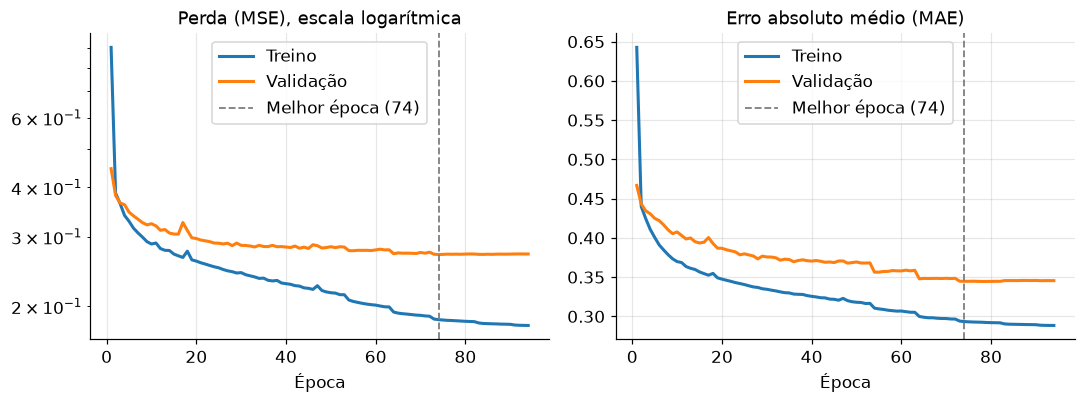

Melhor época (74): MSE treino = 0.1851 | MSE validação = 0.2705
                   MAE treino = 0.2933 | MAE validação = 0.3446


In [20]:
grafico_curvas(hist_reg, metricas=["loss", "mae"],
               titulos=["Perda (MSE), escala logarítmica", "Erro absoluto médio (MAE)"],
               ficheiro="reg_02_curvas_treino.png", melhor_epoca=melhor_epoca_reg,
               escala_log=("loss",))

i = melhor_epoca_reg - 1
print(f"Melhor época ({melhor_epoca_reg}): MSE treino = {hist_reg['loss'][i]:.4f} | "
      f"MSE validação = {hist_reg['val_loss'][i]:.4f}")
print(f"{'':>18} MAE treino = {hist_reg['mae'][i]:.4f} | MAE validação = {hist_reg['val_mae'][i]:.4f}")

**Leitura das curvas.** A perda cai muito nas primeiras épocas (o MSE de validação passa de 0,446 na 1.ª época para 0,324 na 10.ª) e depois desce devagar. A partir da época 48, aproximadamente, a perda de validação fica a menos de 5 % do seu mínimo e quase não melhora, enquanto a de treino continua a descer: a rede começa a ajustar-se a particularidades dos dados de treino. O sobreajuste é ligeiro, porque a perda de validação estabiliza sem voltar a subir; na melhor época (74), o MAE é de 0,293 no treino e de 0,345 na validação. A curva de validação oscila mais do que a de treino, porque a perda de treino é uma média ao longo de toda a época, enquanto a de validação é medida num único ponto, no fim de cada época, e reflete o "ruído" dos passos de otimização. As 5 reduções da taxa de aprendizagem atenuam essas oscilações na fase final. O treino parou na época 94, 20 épocas depois do mínimo da perda de validação.

### 2.8 Avaliação no conjunto de teste

In [21]:
# Avaliação com o Keras: perda (MSE) e métricas definidas na compilação
res_reg = modelo_reg.evaluate(X_teste_reg_p, y_teste_reg, verbose=0, return_dict=True)
print(f"Keras -> MSE: {res_reg['loss']:.4f} | MAE: {res_reg['mae']:.4f} | RMSE: {res_reg['rmse']:.4f}")

# As mesmas métricas com o scikit-learn, a partir das previsões, mais o R²
prev_rede = modelo_reg.predict(X_teste_reg_p, verbose=0).ravel()
metricas_rede = metricas_regressao(y_teste_reg, prev_rede)

tabela_reg = pd.concat([referencias, pd.DataFrame({"Rede neuronal (MLP)": metricas_rede}).T])
tabela_reg["MAE (USD)"] = (tabela_reg["MAE"] * 100_000).round(-2).astype(int)
tabela_reg["RMSE (USD)"] = (tabela_reg["RMSE"] * 100_000).round(-2).astype(int)
display(tabela_reg.round(4))

melhoria_rmse = 1 - metricas_rede["RMSE"] / referencias.loc["Regressão linear", "RMSE"]
melhoria_mae = 1 - metricas_rede["MAE"] / referencias.loc["Regressão linear", "MAE"]
print(f"Face à regressão linear, a rede reduz o RMSE em {melhoria_rmse:.1%} e o MAE em {melhoria_mae:.1%}.")
print(f"Previsões da rede entre {prev_rede.min():.3f} e {prev_rede.max():.3f} "
      f"(valores reais entre {y_teste_reg.min():.3f} e {y_teste_reg.max():.3f}).")

Keras -> MSE: 0.2627 | MAE: 0.3404 | RMSE: 0.5125


,MAE,RMSE,R²,MAE (USD),RMSE (USD)
Média do treino,0.9051,1.1448,-0.0001,90500,114500
Regressão linear,0.5335,0.7446,0.5769,53300,74500
Rede neuronal (MLP),0.3404,0.5125,0.7995,34000,51300


Face à regressão linear, a rede reduz o RMSE em 31.2% e o MAE em 36.2%.
Previsões da rede entre 0.273 e 5.849 (valores reais entre 0.150 e 5.000).


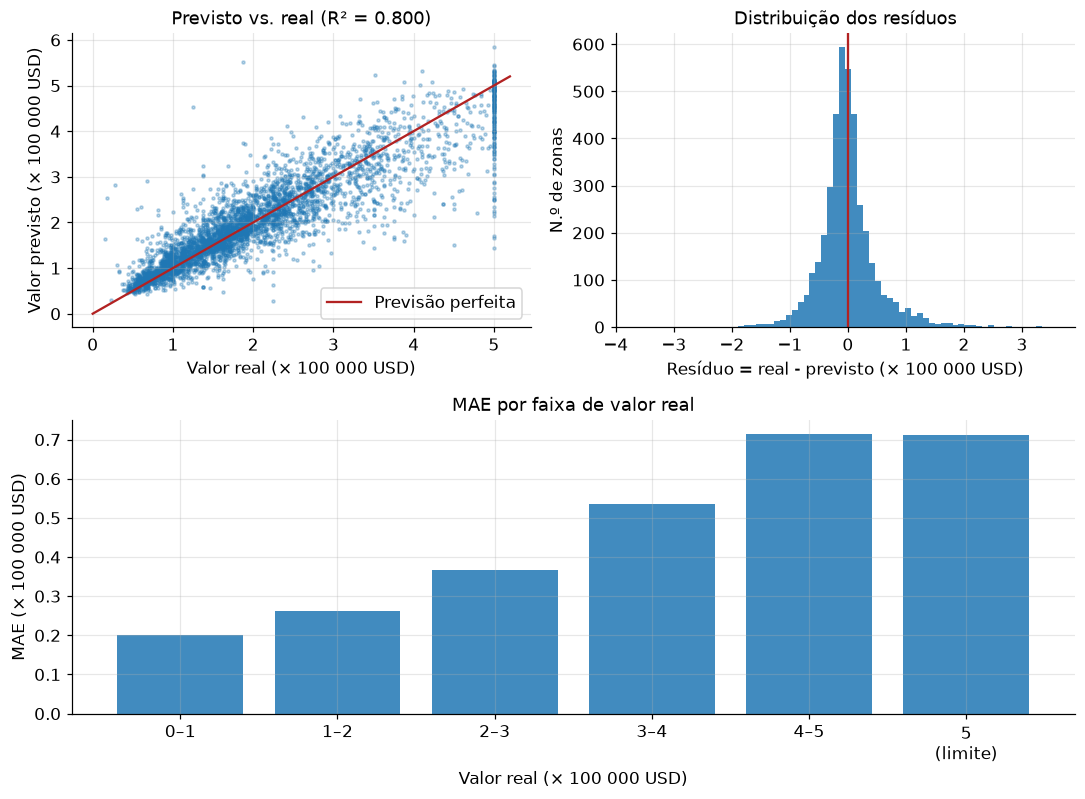

              MAE  n.º de zonas
0–1         0.200           730
1–2         0.262          1684
2–3         0.368           956
3–4         0.535           415
4–5         0.714           159
5 (limite)  0.711           184


In [22]:
residuos = y_teste_reg - prev_rede
fig = plt.figure(figsize=(10, 7.4))
grelha = fig.add_gridspec(2, 2)
eixos = [fig.add_subplot(grelha[0, 0]), fig.add_subplot(grelha[0, 1]), fig.add_subplot(grelha[1, :])]

# (a) Previsto vs. real: num modelo perfeito, todos os pontos estariam sobre a diagonal
eixos[0].scatter(y_teste_reg, prev_rede, s=4, alpha=0.3)
eixos[0].plot([0, 5.2], [0, 5.2], color="firebrick", lw=1.5, label="Previsão perfeita")
eixos[0].set_xlabel("Valor real (× 100 000 USD)")
eixos[0].set_ylabel("Valor previsto (× 100 000 USD)")
eixos[0].set_title(f"Previsto vs. real (R² = {metricas_rede['R²']:.3f})")
eixos[0].legend()

# (b) Distribuição dos resíduos (real - previsto)
eixos[1].hist(residuos, bins=70, color="tab:blue", alpha=0.85)
eixos[1].axvline(0, color="firebrick", lw=1.5)
eixos[1].set_title("Distribuição dos resíduos")
eixos[1].set_xlabel("Resíduo = real - previsto (× 100 000 USD)")
eixos[1].set_ylabel("N.º de zonas")

# (c) Erro absoluto médio por faixa de valor real
faixas = pd.cut(y_teste_reg, bins=[0, 1, 2, 3, 4, 5.0, np.inf], right=False,
                labels=["0–1", "1–2", "2–3", "3–4", "4–5", "5\n(limite)"])
erro_faixa = pd.Series(np.abs(residuos)).groupby(faixas, observed=True).agg(["mean", "size"])
eixos[2].bar(erro_faixa.index.astype(str), erro_faixa["mean"], color="tab:blue", alpha=0.85)
eixos[2].set_title("MAE por faixa de valor real")
eixos[2].set_xlabel("Valor real (× 100 000 USD)")
eixos[2].set_ylabel("MAE (× 100 000 USD)")

fig.tight_layout()
fig.savefig("figuras/reg_03_previsoes.png", dpi=200, bbox_inches="tight")
plt.show()

erro_faixa.index = [str(f).replace("\n", " ") for f in erro_faixa.index]
print(erro_faixa.rename(columns={"mean": "MAE", "size": "n.º de zonas"}).round(3).to_string())

### 2.9 Discussão dos resultados da regressão

- No teste, a rede tem um MAE de **0,340** (≈ 34 000 USD) e um RMSE de **0,513** (≈ 51 300 USD), com **R² = 0,800**: explica cerca de 80 % da variância dos preços, contra 58 % da regressão linear, e reduz o RMSE em 31 % e o MAE em 36 % face a esta. A diferença mostra que a relação entre os atributos e o preço não é linear: o efeito da localização, por exemplo, depende da combinação da latitude com a longitude, e a rede aprende-o sem ser preciso criar esses atributos à mão.
- Os resíduos estão centrados perto de zero (média de 0,002), mas o erro cresce com o valor das casas: o MAE passa de 0,200 na faixa 0–1 para 0,714 na faixa 4–5 e mantém-se nesse nível (0,711) nas 184 zonas de teste com o valor no limite de 5,0. O censo registou "500 000 USD ou mais" como 5,0, por isso o valor verdadeiro destas zonas é desconhecido, e a rede tende a subestimá-lo (no gráfico previsto vs. real, a maioria dos pontos em x = 5 fica abaixo da diagonal).
- A saída linear não tem limites: as previsões vão de 0,273 a 5,849, e as mais altas ultrapassam o máximo registado nos dados (5,0). Para as zonas censuradas, isso até pode estar mais perto do valor real, mas mostra que a rede não conhece as restrições do problema; se fossem necessárias, teriam de ser impostas à parte (por exemplo, limitando as previsões ao intervalo válido).

---
## Parte 3 — Comparação e análise

### 3.1 Diferenças de implementação

Os dois modelos usam os mesmos blocos (camadas `Dense` com ReLU, otimizador Adam, retropropagação e paragem antecipada). O que muda é sobretudo o que está à volta: o formato do alvo, a camada de saída, a função de perda e a forma de avaliar.

| Aspeto | Classificação (Fashion-MNIST) | Regressão (California Housing) |
|:--|:--|:--|
| O que se prevê | Uma de 10 classes (valor discreto) | Um valor contínuo (preço) |
| Entrada | Imagem 28 × 28 → `Flatten` → 784 valores | Vetor de 8 atributos |
| Pré-processamento | Píxeis ÷ 255 → [0, 1] | Padronização *z-score* (ajustada só no treino) |
| Formato do alvo | Inteiros 0–9 | Real entre 0,15 e 5,0 |
| Camada de saída | `Dense(10, activation="softmax")` | `Dense(1, activation="linear")` |
| Função de perda | `sparse_categorical_crossentropy` | `mse` |
| Métricas | Acurácia, precisão, recall, F1 | MAE, RMSE, R² |
| Como se lê a previsão | `argmax` das probabilidades | O próprio valor (× 100 000 USD) |
| Diagnóstico dos erros | Matriz de confusão, exemplos mal classificados | Resíduos, previsto vs. real, erro por faixa |
| Regularização | Dropout + paragem antecipada | Paragem antecipada |

In [23]:
import math

resumo = pd.DataFrame({
    "Classificação (Fashion-MNIST)": [
        "10 classes (inteiros 0-9)",
        f"{fmt(len(X_treino_clf))} / {fmt(len(X_val_clf))} / {fmt(len(X_teste_clf))}",
        "784 → 256 → 128 → 10",
        fmt(modelo_clf.count_params()),
        "Softmax (10 neurónios)",
        "sparse_categorical_crossentropy",
        f"{len(hist_clf['loss'])} ({melhor_epoca_clf})",
        fmt(len(hist_clf["loss"]) * math.ceil(len(X_treino_clf) / 128)),
        f"{tempo_clf:.0f} s ({tempo_clf / len(hist_clf['loss']):.1f} s por época)",
        f"acurácia = {res_clf['accuracy']:.2%}",
    ],
    "Regressão (California Housing)": [
        "valor contínuo (0.15 a 5.0)",
        f"{fmt(len(X_treino_reg))} / {fmt(len(X_val_reg))} / {fmt(len(X_teste_reg))}",
        "8 → 128 → 64 → 32 → 1",
        fmt(modelo_reg.count_params()),
        "Linear (1 neurónio)",
        "mse",
        f"{len(hist_reg['loss'])} ({melhor_epoca_reg})",
        fmt(len(hist_reg["loss"]) * math.ceil(len(X_treino_reg) / 64)),
        f"{tempo_reg:.0f} s ({tempo_reg / len(hist_reg['loss']):.2f} s por época)",
        f"MAE = {metricas_rede['MAE']:.3f} | RMSE = {metricas_rede['RMSE']:.3f} | R² = {metricas_rede['R²']:.3f}",
    ],
}, index=["Alvo", "Treino / validação / teste", "Arquitetura", "Parâmetros treináveis",
          "Camada de saída", "Função de perda", "Épocas executadas (melhor)",
          "Atualizações dos pesos (passos)", "Tempo de treino", "Resultado no teste"])
resumo

,Classificação (Fashion-MNIST),Regressão (California Housing)
Alvo,10 classes (inteiros 0-9),valor contínuo (0.15 a 5.0)
Treino / validação / teste,54 000 / 6 000 / 10 000,13 209 / 3 303 / 4 128
Arquitetura,784 → 256 → 128 → 10,8 → 128 → 64 → 32 → 1
Parâmetros treináveis,235 146,11 521
Camada de saída,Softmax (10 neurónios),Linear (1 neurónio)
Função de perda,sparse_categorical_crossentropy,mse
Épocas executadas (melhor),22 (16),94 (74)
Atualizações dos pesos (passos),9 284,19 458
Tempo de treino,63 s (2.9 s por época),26 s (0.28 s por época)
Resultado no teste,acurácia = 89.16%,MAE = 0.340 | RMSE = 0.513 | R² = 0.800


### 3.2 Experiência: o efeito da escala dos dados

Nos dois problemas pus as entradas numa escala pequena antes do treino. Para medir a importância deste passo, treinei as **mesmas arquiteturas** com e sem ele, com a mesma inicialização dos pesos, um número fixo de épocas (10 na classificação, 100 na regressão) e sem *callbacks*, para a comparação ser justa.

In [24]:
def treinar_classificador(X_tr, X_va, epocas=10):
    """Treina o classificador da Parte 1 durante um número fixo de épocas."""
    keras.utils.set_random_seed(SEMENTE)
    modelo = criar_classificador()
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return modelo.fit(X_tr, y_treino_clf, validation_data=(X_va, y_val_clf),
                      epochs=epocas, batch_size=128, verbose=0).history


def treinar_regressor(X_tr, X_va, epocas=100):
    """Treina o regressor da Parte 2 durante um número fixo de épocas."""
    keras.utils.set_random_seed(SEMENTE)
    modelo = criar_regressor(X_tr.shape[1])
    modelo.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"], steps_per_execution=32)
    return modelo.fit(X_tr, y_treino_reg, validation_data=(X_va, y_val_reg),
                      epochs=epocas, batch_size=64, verbose=0).history


inicio = time.perf_counter()
escala = {
    "clf_normalizado": treinar_classificador(X_treino_clf, X_val_clf),
    "clf_bruto": treinar_classificador(X_treino_clf * 255.0, X_val_clf * 255.0),   # píxeis 0-255
    "reg_padronizado": treinar_regressor(X_treino_reg_p, X_val_reg_p),
    "reg_bruto": treinar_regressor(X_treino_reg, X_val_reg),                      # sem StandardScaler
}
print(f"Experiência concluída em {time.perf_counter() - inicio:.0f} s")

Experiência concluída em 112 s


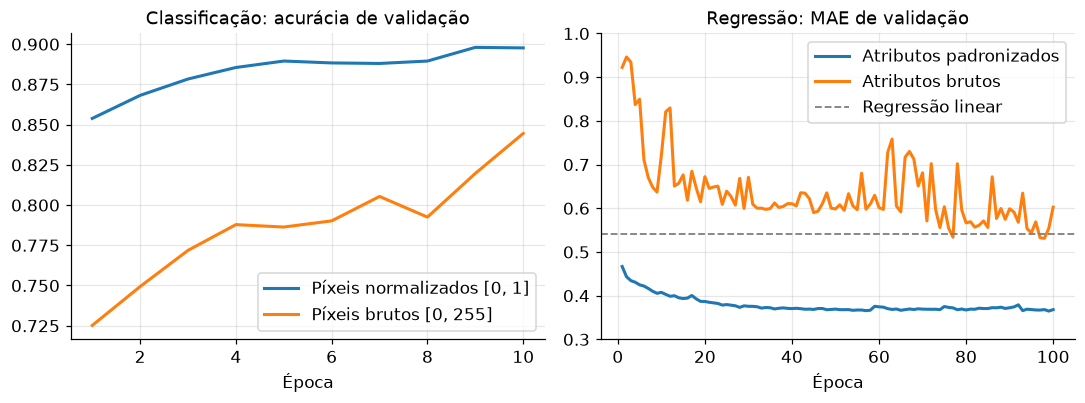

,Com escala adequada,Dados brutos
Classificação: melhor acurácia de validação,0.8980,0.8445
Classificação: acurácia na última época,0.8977,0.8445
Regressão: melhor MAE de validação,0.3647,0.5312
Regressão: MAE na última época,0.3680,0.6025


In [25]:
mae_val_linear = mean_absolute_error(y_val_reg, regressao_linear.predict(X_val_reg_p))

fig, eixos = plt.subplots(1, 2, figsize=(10, 3.8))
ep = np.arange(1, len(escala["clf_normalizado"]["loss"]) + 1)
eixos[0].plot(ep, escala["clf_normalizado"]["val_accuracy"], lw=2, label="Píxeis normalizados [0, 1]")
eixos[0].plot(ep, escala["clf_bruto"]["val_accuracy"], lw=2, label="Píxeis brutos [0, 255]")
eixos[0].set_title("Classificação: acurácia de validação")
eixos[0].set_xlabel("Época")
eixos[0].legend()

ep = np.arange(1, len(escala["reg_padronizado"]["loss"]) + 1)
eixos[1].plot(ep, escala["reg_padronizado"]["val_mae"], lw=2, label="Atributos padronizados")
eixos[1].plot(ep, escala["reg_bruto"]["val_mae"], lw=2, label="Atributos brutos")
eixos[1].axhline(mae_val_linear, color="gray", ls="--", lw=1.2, label="Regressão linear")
eixos[1].set_title("Regressão: MAE de validação")
eixos[1].set_xlabel("Época")
eixos[1].set_ylim(0.3, 1.0)
eixos[1].legend()

fig.tight_layout()
fig.savefig("figuras/cmp_01_escala.png", dpi=200, bbox_inches="tight")
plt.show()

tabela_escala = pd.DataFrame({
    "Com escala adequada": [max(escala["clf_normalizado"]["val_accuracy"]), escala["clf_normalizado"]["val_accuracy"][-1],
                            min(escala["reg_padronizado"]["val_mae"]), escala["reg_padronizado"]["val_mae"][-1]],
    "Dados brutos": [max(escala["clf_bruto"]["val_accuracy"]), escala["clf_bruto"]["val_accuracy"][-1],
                     min(escala["reg_bruto"]["val_mae"]), escala["reg_bruto"]["val_mae"][-1]],
}, index=["Classificação: melhor acurácia de validação", "Classificação: acurácia na última época",
          "Regressão: melhor MAE de validação", "Regressão: MAE na última época"])
tabela_escala.round(4)

**Resultado.** Sem a escala adequada, os dois modelos pioram:

- **Classificação:** com os píxeis entre 0 e 255, a melhor acurácia de validação desce de 89,8 % para 84,5 %, ou seja, a taxa de erro aumenta mais de 50 %. O Adam adapta o passo de cada peso e compensa parte do problema, mas as somas ponderadas da primeira camada ficam 255 vezes maiores e o treino torna-se mais lento e instável (curva laranja do gráfico).
- **Regressão:** com os atributos brutos, o melhor MAE de validação sobe de 0,365 para 0,531 (+46 %), ao nível da regressão linear (0,541), e na última época fica mesmo pior do que ela (0,603), apesar de a rede ser muito mais flexível. Os atributos com valores grandes, como a `Population` (milhares), dominam as somas ponderadas e abafam o `MedInc` (unidades), que é o mais informativo. Com entradas em escalas tão diferentes, a superfície da perda fica muito alongada e o otimizador avança aos ziguezagues, o que explica as oscilações da curva.

A normalização não é um pormenor: sobretudo em regressão, com atributos em escalas muito diferentes, pode pesar mais do que qualquer ajuste à arquitetura.

### 3.3 Desafios específicos de cada tipo de problema

**Classificação**

- **Classes parecidas entre si.** A maior parte dos erros está nas peças de cima do corpo (camisa, T-shirt, camisola, casaco). Um MLP vê a imagem como uma lista de 784 números e perde a estrutura espacial; é aqui que as redes convolucionais fazem a diferença.
- **Acurácia e perda nem sempre andam juntas.** A acurácia só conta se a classe de maior probabilidade é a certa; a entropia cruzada também mede a confiança. A perda de validação pode subir (a rede fica demasiado confiante nos erros) enquanto a acurácia se mantém, e é por isso que a paragem antecipada vigia a perda.
- **Probabilidades pouco fiáveis.** A Softmax devolve números que somam 1, mas a rede está muitas vezes muito confiante quando erra: essas probabilidades não são uma medida calibrada de incerteza.
- **Formato das etiquetas e desequilíbrio.** A perda tem de corresponder ao formato das etiquetas (inteiros → `sparse_categorical_crossentropy`; *one-hot* → `categorical_crossentropy`). Aqui as classes estão equilibradas; num problema desequilibrado, a acurácia engana e é preciso olhar para o F1 por classe ou usar pesos por classe.

**Regressão**

- **Escala dos dados.** Sem padronização, a rede treina pior do que uma simples regressão linear (secção 3.2). Em regressão, também a escala do alvo pesa: um alvo em unidades de dólares (até 500 000) daria perdas MSE da ordem de 10¹⁰ e gradientes enormes.
- **Não existe uma "acurácia".** O MAE e o RMSE dependem da unidade do alvo e só ganham significado quando comparados com uma referência; o R² ajuda a comparar entre problemas.
- **Sensibilidade a valores extremos.** O MSE penaliza os erros ao quadrado, por isso algumas zonas atípicas pesam muito no treino. O MAE ou a perda de Huber são alternativas mais robustas.
- **Qualidade do alvo.** Os valores censurados a 5,0 não correspondem ao preço real, e o erro concentra-se aí. Nenhuma arquitetura corrige um alvo mal medido.
- **Curvas mais ruidosas.** A validação oscila mais e precisa de mais épocas (e de mais paciência na paragem antecipada) do que na classificação.

In [26]:
# Guarda todas as métricas num ficheiro JSON, usado para construir o relatório em PDF
def para_json(obj):
    """Converte tipos do NumPy em tipos nativos do Python."""
    return obj.item() if hasattr(obj, "item") else str(obj)


def camadas(modelo):
    return [{"nome": c.name, "tipo": c.__class__.__name__, "saida": str(tuple(c.output.shape)),
             "parametros": c.count_params()} for c in modelo.layers]


resultados = {
    "versoes": {"python": platform.python_version(), "tensorflow": tf.__version__,
                "keras": keras.__version__, "sklearn": sklearn.__version__,
                "numpy": np.__version__, "pandas": pd.__version__},
    "classificacao": {
        "divisao": [len(X_treino_clf), len(X_val_clf), len(X_teste_clf)],
        "camadas": camadas(modelo_clf), "parametros": modelo_clf.count_params(),
        "perda_inicial": {"sparse": perda_sparse, "onehot": perda_onehot},
        "epocas": len(hist_clf["loss"]), "melhor_epoca": melhor_epoca_clf, "tempo_s": tempo_clf,
        "historico": hist_clf, "teste": res_clf, "relatorio": relatorio_clf,
        "matriz_confusao": matriz.tolist(), "confusoes_top": confusoes_top,
        "n_erros": len(erros),
        "confianca_certas": confianca[y_prev_clf == y_teste_clf].mean(),
        "confianca_erradas": confianca[erros].mean(),
    },
    "regressao": {
        "divisao": [len(X_treino_reg), len(X_val_reg), len(X_teste_reg)],
        "camadas": camadas(modelo_reg), "parametros": modelo_reg.count_params(),
        "n_limite": n_limite, "correlacoes": correlacoes.to_dict(),
        "epocas": len(hist_reg["loss"]), "melhor_epoca": melhor_epoca_reg, "tempo_s": tempo_reg,
        "historico": hist_reg, "teste_keras": res_reg,
        "tabela": tabela_reg.drop(columns=["MAE (USD)", "RMSE (USD)"]).to_dict(orient="index"),
        "melhoria_rmse": melhoria_rmse, "melhoria_mae": melhoria_mae,
        "prev_min": prev_rede.min(), "prev_max": prev_rede.max(),
        "residuo_medio": residuos.mean(),
        "erro_por_faixa": erro_faixa.rename(columns={"mean": "MAE", "size": "n"}).to_dict(orient="index"),
    },
    "escala": {"historicos": escala, "tabela": tabela_escala.to_dict(), "mae_val_linear": mae_val_linear},
}

with open("resultados/metricas.json", "w", encoding="utf-8") as f:
    json.dump(resultados, f, ensure_ascii=False, indent=1, default=para_json)
print("Métricas guardadas em resultados/metricas.json")
print("Figuras guardadas em figuras/:", sorted(os.listdir("figuras")))

Métricas guardadas em resultados/metricas.json
Figuras guardadas em figuras/: ['clf_01_exemplos.png', 'clf_02_curvas_treino.png', 'clf_03_matriz_confusao.png', 'clf_04_erros.png', 'cmp_01_escala.png', 'reg_01_exploracao.png', 'reg_02_curvas_treino.png', 'reg_03_previsoes.png']


## 4. Conclusões

1. Os dois modelos cumprem os requisitos do enunciado e têm bons resultados para redes densas simples: **89,2 %** de acurácia no Fashion-MNIST e **R² = 0,800** (MAE ≈ 34 000 USD) no California Housing, bem acima das referências (10 % num palpite ao acaso; R² = 0,577 na regressão linear).
2. A mesma "máquina" serve os dois problemas: camadas densas com ReLU, otimizador Adam e retropropagação. O que define o tipo de problema é a **camada de saída** (Softmax ou linear), a **função de perda** (entropia cruzada ou MSE) e as **métricas** usadas para avaliar.
3. O pré-processamento pesa tanto como a arquitetura: sem normalizar ou padronizar os dados, os dois modelos pioram e a rede de regressão perde a vantagem que tinha sobre a regressão linear.
4. Os erros que restam têm causas diferentes. Na classificação, vêm sobretudo da arquitetura: o MLP não vê a estrutura espacial das imagens, e uma CNN é o passo natural seguinte. Na regressão, vêm sobretudo dos dados: o alvo está censurado a 5,0 e há zonas atípicas. Aí, as melhorias passam por tratar os dados (prever o logaritmo do preço, usar a perda de Huber) e por validação cruzada, mais do que por aumentar a rede.